In [1]:
import pandas as pd

df = pd.read_excel("OnlineRetail.xlsx")

print(df.shape)
display(df.head())

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print("Missing values by column:")
display(df.isna().sum().to_frame("Missing"))

print("Duplicate rows:", df.duplicated().sum())
print("Cancellation invoices:",
    df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Rows with zero or negative quantity:",
    (df["Quantity"]<=0).sum())
print("Rows with zero or negative unit price:",
    (df["UnitPrice"] <= 0).sum())


Missing values by column:


,Missing
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Duplicate rows: 5268
Cancellation invoices: 9288
Rows with zero or negative quantity: 10624
Rows with zero or negative unit price: 2517


In [3]:
df_clean = df.copy()
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)

valid_purchases = (
    df_clean["CustomerID"].notna()
    & ~df_clean["InvoiceNo"].str.startswith("C")
    & (df_clean["Quantity"]>0)
    & (df_clean["UnitPrice"]>0)
)

customer_sales = df_clean.loc[valid_purchases].drop_duplicates().copy()
customer_sales["Sales"] = customer_sales["Quantity"] * customer_sales["UnitPrice"]

print("Rows for customer analysis", customer_sales.shape[0])
print("Identified customers:", customer_sales["CustomerID"].nunique())
print("Date range:",
    customer_sales["InvoiceDate"].min(),
    customer_sales["InvoiceDate"].max())

Rows for customer analysis 392692
Identified customers: 4338
Date range: 2010-12-01 08:26:00 2011-12-09 12:50:00


In [4]:
customer_summary = (
    customer_sales.groupby("CustomerID")
    .agg(
        orders = ("InvoiceNo", "nunique"),
        total_spend=("Sales", "sum"),
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

customer_summary["customer_type"] = customer_summary["orders"].apply(
    lambda orders: "Repeat" if orders >=2 else "One-time"
)

print("Repeat customer rate:",
      round((customer_summary["orders"] >=2).mean() * 100, 1), "%")
display(customer_summary.head())

Repeat customer rate: 65.6 %


,CustomerID,orders,total_spend,first_purchase,last_purchase,customer_type
0,12346.0,1,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,One-time
1,12347.0,7,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00,Repeat
2,12348.0,4,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00,Repeat
3,12349.0,1,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00,One-time
4,12350.0,1,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00,One-time


In [5]:
reference_date = customer_sales["InvoiceDate"].max()

customer_summary["days_since_last_order"] = (
    reference_date - customer_summary["last_purchase"]
).dt.days

display(customer_summary["days_since_last_order"].describe())

count    4338.000000
mean       91.536422
std       100.014169
min         0.000000
25%        17.000000
50%        50.000000
75%       141.000000
max       373.000000
Name: days_since_last_order, dtype: float64

In [6]:
customer_summary["segment"] = "One-time customer"

repeat_recent = (
    (customer_summary["orders"]>=2)
    & (customer_summary["days_since_last_order"]<=90)
)

repeat_lapsed = (
    (customer_summary["orders"]>=2)
    & (customer_summary["days_since_last_order"]>90)
)

customer_summary.loc[repeat_recent, "segment"] = "Repeat customer, recent"
customer_summary.loc[repeat_lapsed, "segment"] = "Repeat customer, lapsed"

segment_summary = (
    customer_summary.groupby("segment")
    .agg(
        customers=("CustomerID", "count"),
        avg_orders=("orders", "mean"),
        avg_spend=("total_spend", "mean")
    )
    .reset_index()
)

segment_summary["percent_of_customers"] = (
    segment_summary["customers"] / len(customer_summary) * 100
).round(1)

display(segment_summary.round(1))

,segment,customers,avg_orders,avg_spend,percent_of_customers
0,One-time customer,1493,1.0,411.2,34.4
1,"Repeat customer, lapsed",599,3.1,1126.5,13.8
2,"Repeat customer, recent",2246,6.8,3383.1,51.8


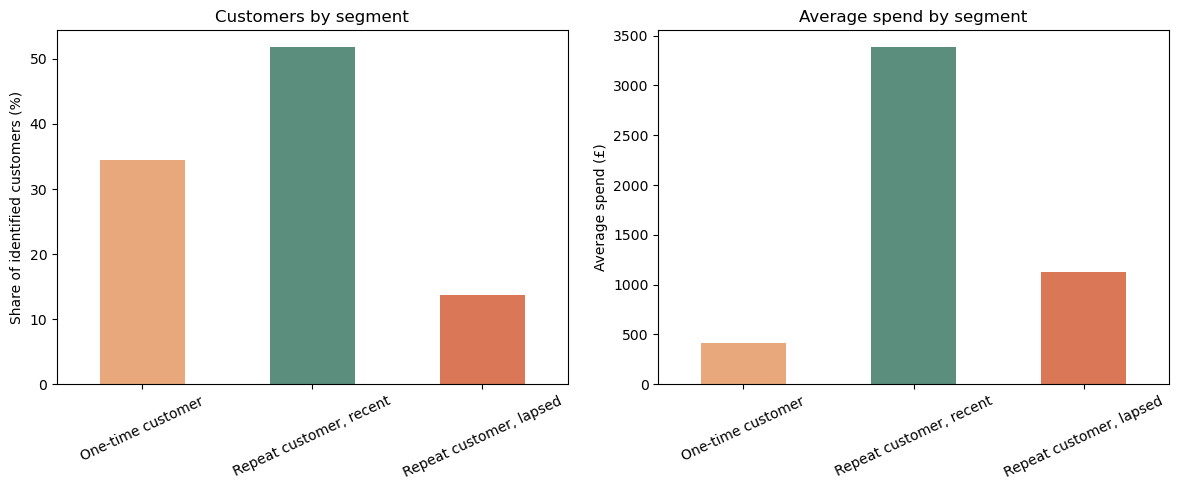

In [7]:
import matplotlib.pyplot as plt

plot_data = (
segment_summary
.set_index("segment")
.reindex([
"One-time customer",
"Repeat customer, recent",
"Repeat customer, lapsed"
])
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data["percent_of_customers"].plot(
kind="bar", ax=axes[0], color=["#E8A87C", "#5B8E7D", "#D97757"]
)
axes[0].set_title("Customers by segment")
axes[0].set_ylabel("Share of identified customers (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

plot_data["avg_spend"].plot(
kind="bar", ax=axes[1], color=["#E8A87C", "#5B8E7D", "#D97757"]
)
axes[1].set_title("Average spend by segment")
axes[1].set_ylabel("Average spend (£)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


Identified customers: 4,338
Repeat customer rate: 65.6%
Repeat customers with no order in 90+ days: 599 (21.1% of repeat customers)


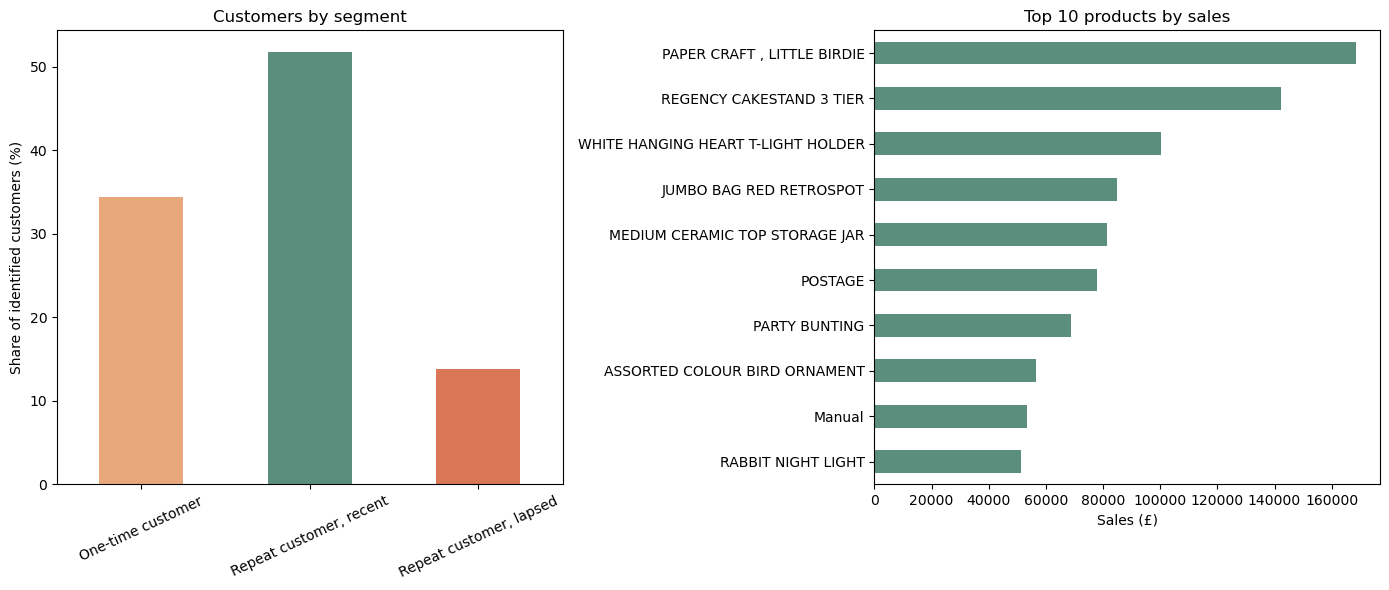

Top products by sales:


,Sales (£)
Description,
"PAPER CRAFT , LITTLE BIRDIE",168469.60
REGENCY CAKESTAND 3 TIER,142264.75
WHITE HANGING HEART T-LIGHT HOLDER,100392.10
JUMBO BAG RED RETROSPOT,85040.54
MEDIUM CERAMIC TOP STORAGE JAR,81416.73
POSTAGE,77803.96
PARTY BUNTING,68785.23
ASSORTED COLOUR BIRD ORNAMENT,56413.03
Manual,53419.93


In [8]:
import matplotlib.pyplot as plt

# Customer retention summary
repeat_customers = customer_summary[customer_summary["orders"] >= 2]
lapsed_repeat = customer_summary[
customer_summary["segment"] == "Repeat customer, lapsed"
]

repeat_rate = len(repeat_customers) / len(customer_summary) * 100
lapsed_repeat_rate = len(lapsed_repeat) / len(repeat_customers) * 100

print(f"Identified customers: {len(customer_summary):,}")
print(f"Repeat customer rate: {repeat_rate:.1f}%")
print(
f"Repeat customers with no order in 90+ days: "
f"{len(lapsed_repeat):,} ({lapsed_repeat_rate:.1f}% of repeat customers)"
)

# Top 10 products by sales value
top_products = (
customer_sales.dropna(subset=["Description"])
.groupby("Description")
.agg(sales=("Sales", "sum"))
.nlargest(10, "sales")
.sort_values("sales")
)

# Two project visuals
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

segment_plot = (
segment_summary.set_index("segment")["percent_of_customers"]
.reindex([
"One-time customer",
"Repeat customer, recent",
"Repeat customer, lapsed"
])
)

segment_plot.plot(
kind="bar",
ax=axes[0],
color=["#E8A87C", "#5B8E7D", "#D97757"]
)
axes[0].set_title("Customers by segment")
axes[0].set_ylabel("Share of identified customers (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

top_products["sales"].plot(kind="barh", ax=axes[1], color="#5B8E7D")
axes[1].set_title("Top 10 products by sales")
axes[1].set_xlabel("Sales (£)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

print("Top products by sales:")
display(
top_products.sort_values("sales", ascending=False)
.round(2)
.rename(columns={"sales": "Sales (£)"})
)
